       mfcc_1      mfcc_2      mfcc_3      mfcc_4     mfcc_5     mfcc_6  \
0 -654.655804  119.375134  -24.098016  -48.390246  -8.711785 -15.786432   
1 -515.996802  149.656261  -63.029594  -80.193611 -10.045637 -22.980422   
2 -474.776025  181.182785  -71.926566 -103.568912 -20.996247 -22.444298   
3 -578.314824  210.039484  -86.978886 -107.073763  -6.334317 -18.731336   
4 -676.041623  247.277357 -134.278791 -102.305808  20.942173 -35.089295   

      mfcc_7     mfcc_8     mfcc_9    mfcc_10    mfcc_11    mfcc_12  \
0 -41.391101 -30.992024 -12.044214 -12.869910 -16.395834 -13.309184   
1 -52.023706 -21.952631  -0.456912 -17.668566 -22.365966 -11.567680   
2 -49.002811 -17.346423   1.005665 -25.755892 -32.110253 -12.903853   
3 -53.237194 -20.387208 -11.111788 -40.403250 -33.368031 -11.030578   
4 -67.175560 -19.761831 -26.120526 -47.911162 -27.649232 -19.478730   

     mfcc_13     centroid   bandwidth   contrast       zcr label  
0 -12.605136  1300.785829  825.001627  20.367815  0.043

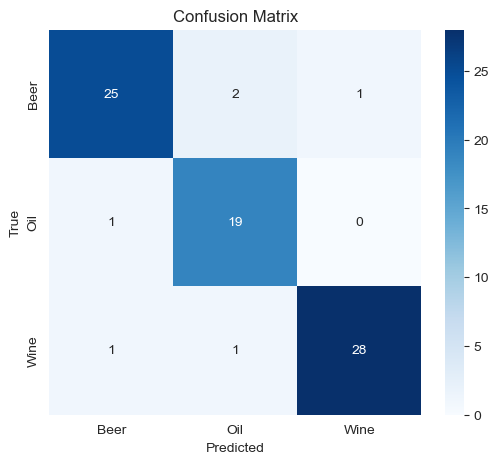

In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# === 1. Load dataset ===
df = pd.read_csv("liquid_audio_features_filtered.csv")
print(df.head())

# === 2. Split features and labels ===
X = df.drop("label", axis=1).values
y = df["label"].values

# === 3. Encode labels ===
le = LabelEncoder()
y_encoded = le.fit_transform(y)
print("Label mapping:", dict(zip(le.classes_, le.transform(le.classes_))))

# === 4. Train/Test Split ===
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# === 5. Optional - Scale features ===
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# === 6. Train Classifier ===
clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train, y_train)

# === 7. Evaluate ===
y_pred = clf.predict(X_test)
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=le.classes_))

# === 8. Confusion Matrix ===
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", xticklabels=le.classes_, yticklabels=le.classes_, cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()
